# BESS Dispatch Optimizer — Module 2: LP Optimizer
Run cells top-to-bottom. Uses mock LMP data — no NYISO access needed.

In [3]:
import sys, pathlib
sys.path.insert(0, str(pathlib.Path.cwd()))

from data_fetch import generate_mock_lmp, load_lmp
from optimizer import BatteryConfig, solve, solve_rolling
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import matplotlib.patches as mpatches
import numpy as np

DB    = "bess_lmp.db"
NODE  = "CAPITL"
START = "2025-01-01"
END   = "2025-01-07"

print("Imports OK")

Imports OK


In [ ]:
# ── 1. Generate data & define battery ─────────────────────────────────────
generate_mock_lmp(START, END, node=NODE, db_path=DB, seed=42)
lmp = load_lmp(START, END, node=NODE, db_path=DB)

cfg = BatteryConfig(
    power_mw    = 10.0,   # MW rated power
    energy_mwh  = 40.0,   # MWh capacity  → 4-hour duration
    rte         = 0.85,   # round-trip efficiency
    soc_min_frac= 0.10,   # hold ≥10% SoC
    soc_max_frac= 0.90,   # charge to ≤90% SoC
)
print(f"Battery : {cfg.power_mw} MW / {cfg.energy_mwh} MWh  RTE={cfg.rte:.0%}")
print(f"SoC range: {cfg.e_min:.1f}–{cfg.e_max:.1f} MWh")
print(f"One-way η: {cfg.eta_one_way:.4f}"
print(f"LMP rows : {len(lmp)}")

Battery : 10.0 MW / 40.0 MWh  RTE=85%
SoC range: 4.0–36.0 MWh
One-way η: 0.9220
LMP rows : 168


In [5]:
# ── 2a. Single-horizon solve (whole week at once) ─────────────────────────
result_single = solve(lmp, cfg)
print("=== Single-horizon ===")
print(result_single.summary())

=== Single-horizon ===
Status          : Optimal
Total revenue   : $9,424.89
Charge total    : 471.8 MWh
Discharge total : 415.8 MWh
Equiv. cycles   : 10.39
Hours optimised : 168


In [6]:
# ── 2b. Rolling daily solve (day-ahead, SoC carries over) ─────────────────
result = solve_rolling(lmp, cfg)
print("=== Rolling daily ===")
print(result.summary())
df = result.dispatch
df.head()

=== Rolling daily ===
Status          : Optimal
Total revenue   : $9,147.19
Charge total    : 476.5 MWh
Discharge total : 419.8 MWh
Equiv. cycles   : 10.49
Hours optimised : 168


,interval_start,lmp,charge_mw,discharge_mw,net_mw,soc_mwh,revenue_$
0,2025-01-01 00:00:00,31.227255,0.0,0.000000,0.000000,20.000000,0.000000
1,2025-01-01 01:00:00,25.894751,10.0,0.000000,-10.000000,29.219544,-258.947509
2,2025-01-01 02:00:00,33.279530,0.0,0.000000,0.000000,29.219544,0.000000
3,2025-01-01 03:00:00,34.860682,0.0,2.248729,2.248729,26.780456,78.392224
4,2025-01-01 04:00:00,25.579241,10.0,0.000000,-10.000000,36.000000,-255.792413


In [7]:
# ── 3. Assertions ─────────────────────────────────────────────────────────
assert result.status == "Optimal"
assert (df["charge_mw"] >= -1e-6).all(),    "charge must be ≥ 0"
assert (df["discharge_mw"] >= -1e-6).all(), "discharge must be ≥ 0"
assert (df["charge_mw"] <= cfg.power_mw + 1e-6).all(), "charge MW limit"
assert (df["discharge_mw"] <= cfg.power_mw + 1e-6).all(), "discharge MW limit"
assert (df["soc_mwh"] >= cfg.e_min - 1e-4).all(), "SoC min violated"
assert (df["soc_mwh"] <= cfg.e_max + 1e-4).all(), "SoC max violated"
simultaneous = (df["charge_mw"] > 1e-4) & (df["discharge_mw"] > 1e-4)
assert not simultaneous.any(), "simultaneous charge+discharge detected"
print("✅ All constraint assertions passed")

✅ All constraint assertions passed


In [8]:
# ── 4. Daily P&L summary ──────────────────────────────────────────────────
df["date"] = df["interval_start"].dt.date
daily = df.groupby("date").agg(
    revenue   = ("revenue_$",     "sum"),
    charge    = ("charge_mw",     "sum"),
    discharge = ("discharge_mw",  "sum"),
    avg_lmp   = ("lmp",           "mean"),
).reset_index()
daily["cycles"] = daily["discharge"] / cfg.energy_mwh
daily["$/cycle"] = daily["revenue"] / daily["cycles"].replace(0, float("nan"))
print(daily[["date","revenue","cycles","$/cycle","avg_lmp"]].to_string(index=False))

      date     revenue   cycles     $/cycle   avg_lmp
2025-01-01 2324.367537 1.531345 1517.859806 43.629393
2025-01-02 1952.948907 1.475127 1323.919062 44.761382
2025-01-03  877.538341 1.475127  594.889981 39.019328
2025-01-04  677.910483 1.475127  459.560723 28.907835
2025-01-05  678.102229 1.375064  493.142462 28.700157
2025-01-06 1843.433654 1.687627 1092.322846 43.051467
2025-01-07  792.893592 1.475127  537.508655 39.038132


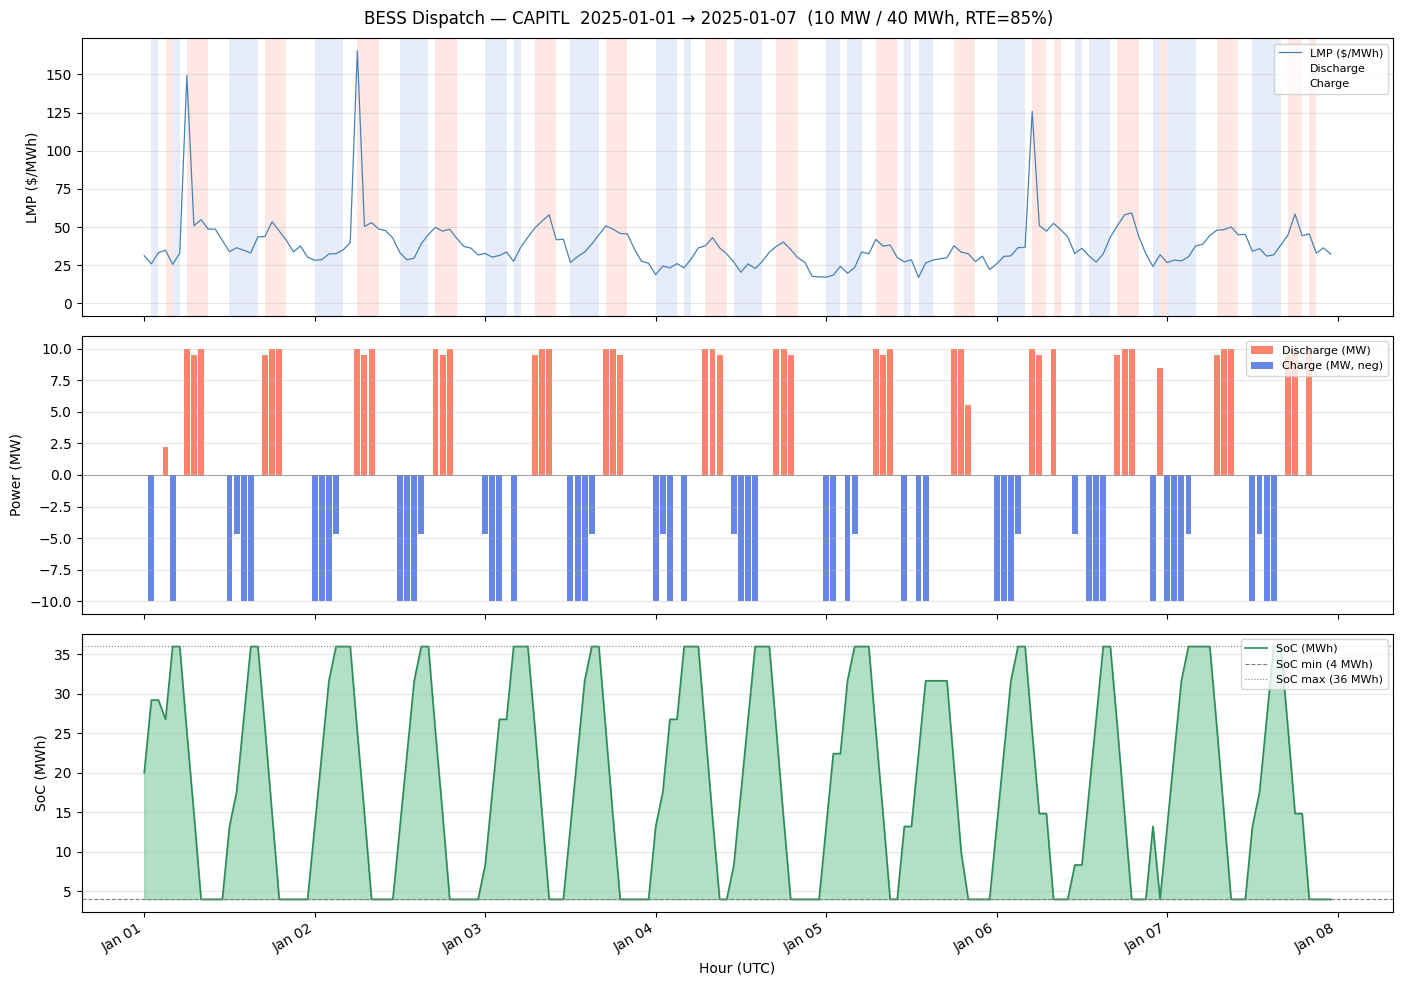

Saved dispatch_chart.png


In [9]:
# ── 5. Full dispatch chart ────────────────────────────────────────────────
fig, axes = plt.subplots(3, 1, figsize=(14, 10), sharex=True)
fig.suptitle(f"BESS Dispatch — {NODE}  {START} → {END}  "
             f"({cfg.power_mw:.0f} MW / {cfg.energy_mwh:.0f} MWh, RTE={cfg.rte:.0%})",
             fontsize=12)

ts = df["interval_start"]

# Panel 1: LMP + dispatch actions
ax1 = axes[0]
ax1.plot(ts, df["lmp"], color="steelblue", lw=0.9, label="LMP ($/MWh)", zorder=3)
ax1.fill_between(ts, 0, df["discharge_mw"] * 0,  # invisible — just for legend
                 color="tomato", alpha=0, label="Discharge")
ax1.fill_between(ts, 0, df["charge_mw"] * 0,
                 color="royalblue", alpha=0, label="Charge")
for _, row in df[df["discharge_mw"] > 0.1].iterrows():
    ax1.axvspan(row["interval_start"],
                row["interval_start"] + pd.Timedelta("1h"),
                color="tomato", alpha=0.15, lw=0)
for _, row in df[df["charge_mw"] > 0.1].iterrows():
    ax1.axvspan(row["interval_start"],
                row["interval_start"] + pd.Timedelta("1h"),
                color="royalblue", alpha=0.12, lw=0)
ax1.set_ylabel("LMP ($/MWh)")
ax1.legend(loc="upper right", fontsize=8)
ax1.grid(axis="y", alpha=0.3)

# Panel 2: Charge / Discharge power
ax2 = axes[1]
ax2.bar(ts, df["discharge_mw"],  width=pd.Timedelta("50min"),
        color="tomato",     alpha=0.8, label="Discharge (MW)")
ax2.bar(ts, -df["charge_mw"],   width=pd.Timedelta("50min"),
        color="royalblue",  alpha=0.8, label="Charge (MW, neg)")
ax2.axhline(0, color="gray", lw=0.5)
ax2.set_ylabel("Power (MW)")
ax2.legend(loc="upper right", fontsize=8)
ax2.grid(axis="y", alpha=0.3)

# Panel 3: State of charge
ax3 = axes[2]
ax3.fill_between(ts, cfg.e_min, df["soc_mwh"], color="mediumseagreen", alpha=0.4)
ax3.plot(ts, df["soc_mwh"], color="seagreen", lw=1.2, label="SoC (MWh)")
ax3.axhline(cfg.e_min, color="gray", lw=0.8, ls="--", label=f"SoC min ({cfg.e_min:.0f} MWh)")
ax3.axhline(cfg.e_max, color="gray", lw=0.8, ls=":",  label=f"SoC max ({cfg.e_max:.0f} MWh)")
ax3.set_ylabel("SoC (MWh)")
ax3.set_xlabel("Hour (UTC)")
ax3.legend(loc="upper right", fontsize=8)
ax3.grid(axis="y", alpha=0.3)

for ax in axes:
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %d"))
    ax.xaxis.set_major_locator(mdates.DayLocator())
    plt.setp(ax.xaxis.get_majorticklabels(), rotation=30, ha="right")

plt.tight_layout()
plt.savefig("dispatch_chart.png", dpi=150)
plt.show()
print("Saved dispatch_chart.png")

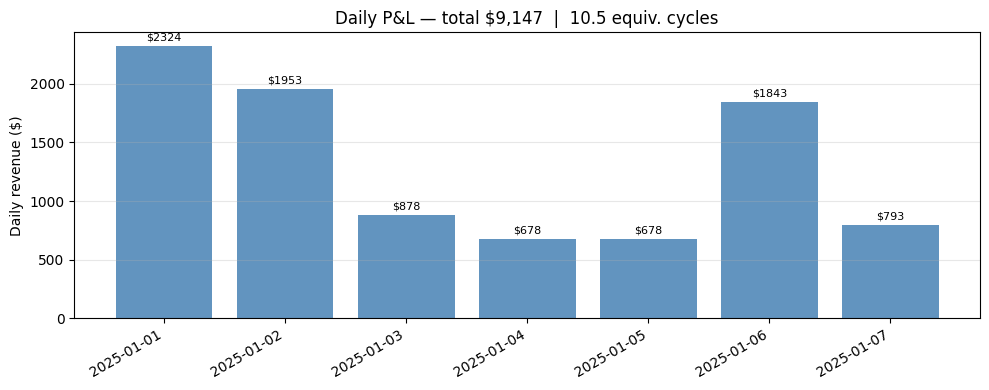


Total weekly revenue : $9,147.19
Equivalent cycles    : 10.49
Revenue per cycle    : $871.61


In [10]:
# ── 6. Daily revenue bar chart ────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(10, 4))
colors = ["tomato" if r < 0 else "steelblue" for r in daily["revenue"]]
ax.bar(range(len(daily)), daily["revenue"], color=colors, alpha=0.85)
ax.set_xticks(range(len(daily)))
ax.set_xticklabels([str(d) for d in daily["date"]], rotation=30, ha="right")
ax.set_ylabel("Daily revenue ($)")
ax.set_title(f"Daily P&L — total ${result.total_revenue:,.0f}  |  {result.equiv_cycles:.1f} equiv. cycles")
for i, row in daily.iterrows():
    ax.text(i, row["revenue"] + 30, f"${row['revenue']:.0f}",
            ha="center", va="bottom", fontsize=8)
ax.axhline(0, color="gray", lw=0.5)
ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.savefig("daily_pnl.png", dpi=150)
plt.show()
print(f"\nTotal weekly revenue : ${result.total_revenue:,.2f}")
print(f"Equivalent cycles    : {result.equiv_cycles:.2f}")
print(f"Revenue per cycle    : ${result.total_revenue / result.equiv_cycles:,.2f}")

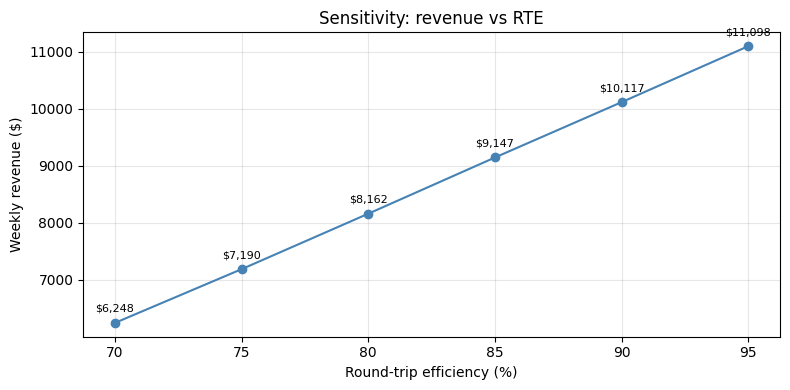


RTE sensitivity:
  RTE=70%  →  $6,247.63
  RTE=75%  →  $7,189.60
  RTE=80%  →  $8,161.88
  RTE=85%  →  $9,147.19
  RTE=90%  →  $10,117.38
  RTE=95%  →  $11,098.42


In [11]:
# ── 7. Sensitivity: vary RTE ──────────────────────────────────────────────
rte_vals = [0.70, 0.75, 0.80, 0.85, 0.90, 0.95]
revenues = []
for rte in rte_vals:
    c = BatteryConfig(power_mw=cfg.power_mw, energy_mwh=cfg.energy_mwh,
                      rte=rte, soc_min_frac=cfg.soc_min_frac, soc_max_frac=cfg.soc_max_frac)
    r = solve_rolling(lmp, c)
    revenues.append(r.total_revenue)

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot([r * 100 for r in rte_vals], revenues, marker="o", color="steelblue")
ax.set_xlabel("Round-trip efficiency (%)")
ax.set_ylabel("Weekly revenue ($)")
ax.set_title("Sensitivity: revenue vs RTE")
ax.grid(alpha=0.3)
for rte, rev in zip(rte_vals, revenues):
    ax.annotate(f"${rev:,.0f}", (rte * 100, rev),
                textcoords="offset points", xytext=(0, 8), ha="center", fontsize=8)
plt.tight_layout()
plt.show()
print("\nRTE sensitivity:")
for rte, rev in zip(rte_vals, revenues):
    print(f"  RTE={rte:.0%}  →  ${rev:,.2f}")

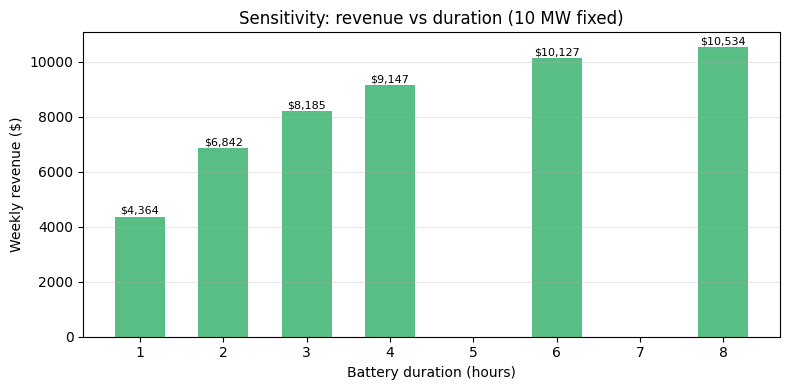


Duration sensitivity:
  1h (10 MWh)  →  $4,363.58
  2h (20 MWh)  →  $6,841.89
  3h (30 MWh)  →  $8,184.54
  4h (40 MWh)  →  $9,147.19
  6h (60 MWh)  →  $10,126.53
  8h (80 MWh)  →  $10,533.52


In [12]:
# ── 8. Sensitivity: vary duration (MWh at fixed MW) ──────────────────────
durations = [1, 2, 3, 4, 6, 8]  # hours
dur_revenues = []
for dur in durations:
    c = BatteryConfig(power_mw=cfg.power_mw, energy_mwh=cfg.power_mw * dur,
                      rte=cfg.rte, soc_min_frac=cfg.soc_min_frac, soc_max_frac=cfg.soc_max_frac)
    r = solve_rolling(lmp, c)
    dur_revenues.append(r.total_revenue)

fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(durations, dur_revenues, color="mediumseagreen", alpha=0.85, width=0.6)
ax.set_xlabel("Battery duration (hours)")
ax.set_ylabel("Weekly revenue ($)")
ax.set_title(f"Sensitivity: revenue vs duration ({cfg.power_mw:.0f} MW fixed)")
ax.grid(axis="y", alpha=0.3)
for dur, rev in zip(durations, dur_revenues):
    ax.text(dur, rev + 30, f"${rev:,.0f}", ha="center", va="bottom", fontsize=8)
plt.tight_layout()
plt.show()
print("\nDuration sensitivity:")
for dur, rev in zip(durations, dur_revenues):
    print(f"  {dur}h ({cfg.power_mw*dur:.0f} MWh)  →  ${rev:,.2f}")

In [13]:
print("\n✅ optimizer.py is working. Next: build reporting.py for the P&L dashboard.")


✅ optimizer.py is working. Next: build reporting.py for the P&L dashboard.
